# CS 179 Project — Bayesian Skill Estimation for StarCraft
Bradley-Terry latent skill model compared across SVI and MCMC (NUTS).

## 1. Imports & Setup

In [6]:
import numpy as np
import torch
import time
import matplotlib.pyplot as plt
import pyro
import pyro.infer
import pyro.optim
import pyro.distributions as dist
import numpyro
import numpyro.distributions as dist_np
import jax
import jax.numpy as jnp
from numpyro.infer import MCMC, NUTS
from numpyro.diagnostics import summary
from IPython.display import clear_output

seed = 179
np.random.seed(seed)
pyro.set_rng_seed(seed)

## 2. Data Loading

In [7]:
with open('data/train.csv') as f:
    lines = f.read().split('\n')

playerid = {}; p = 0
for line in lines:
    csv = line.split(',')
    if len(csv) != 10: continue
    for name in [csv[1], csv[4]]:
        if name not in playerid: playerid[name] = p; p += 1

nplayers = len(playerid)
playername = [''] * nplayers
for name, idx in playerid.items(): playername[idx] = name

pKeep, nEdge, nKeep = 1.0, 3, 5
nplays = np.zeros((nplayers, nplayers))
nwins  = np.zeros((nplayers, nplayers))

for line in lines:
    csv = line.split(',')
    if len(csv) != 10: continue
    a, b = playerid[csv[1]], playerid[csv[4]]
    aw, bw = csv[2] == '[winner]', csv[5] == '[winner]'
    if np.random.rand() < pKeep:
        if (nplays[a,b] < nKeep) and (
            (nplays[a,:]>0).sum() < nEdge or (nplays[:,b]>0).sum() < nEdge
        ):
            nplays[a,b] += 1; nplays[b,a] += 1
            nwins[a,b]  += aw; nwins[b,a]  += bw

pairs  = [(a, b) for a in range(nplayers) for b in range(a+1, nplayers) if nplays[a,b] > 0]
a_idx  = torch.tensor([p[0] for p in pairs], dtype=torch.long)
b_idx  = torch.tensor([p[1] for p in pairs], dtype=torch.long)
wins   = torch.tensor([nwins[p[0], p[1]]  for p in pairs], dtype=torch.float)
plays  = torch.tensor([nplays[p[0], p[1]] for p in pairs], dtype=torch.float)

print(f'Players: {nplayers} | Observed pairs: {len(pairs)} | Total games: {int(plays.sum())}')

Players: 999 | Observed pairs: 2988 | Total games: 4677


In [8]:
with open('data/valid.csv') as f:
    vlines = f.read().split('\n')

val_matches = []
for line in vlines:
    csv = line.split(',')
    if len(csv) != 10: continue
    p0, p1 = csv[1], csv[4]
    if p0 not in playerid or p1 not in playerid: continue
    a, b = playerid[p0], playerid[p1]
    winner = a if csv[2] == '[winner]' else b
    val_matches.append((a, b, winner))

print(f'Validation matches: {len(val_matches)}')

Validation matches: 94007


## 3. Model (Shared)

Each player $i$ has a latent skill $s_i \sim \mathcal{N}(0,1)$. Win probability is $\sigma(s_a - s_b)$, giving:
$$w_{ab} \sim \operatorname{Binomial}\!\left(n_{ab},\; \sigma(s_a - s_b)\right)$$
This same `model` function is used by both SVI and MCMC below.

In [9]:
pyro.get_param_store().clear()

def model(a_idx, b_idx, wins, plays, nplayers):
    with pyro.plate('players', nplayers):
        s = pyro.sample('s', dist.Normal(torch.zeros(nplayers), torch.ones(nplayers)))
    prob = torch.sigmoid(s[a_idx] - s[b_idx])
    with pyro.plate('matches', len(a_idx)):
        pyro.sample('obs', dist.Binomial(total_count=plays, probs=prob), obs=wins)

---
# Part A: Stochastic Variational Inference (SVI)

### A1. Guide (Mean-Field Variational Posterior)

Mean-field approximation: $q(s_i) = \mathcal{N}(\bar{s}_i, \sigma_i^2)$ with learnable $\bar{s}_i$ and $\sigma_i > 0$.

In [10]:
def guide(a_idx, b_idx, wins, plays, nplayers):
    s_mean = pyro.param('s_mean', torch.zeros(nplayers))
    s_std  = pyro.param('s_std',  0.1 * torch.ones(nplayers),
                         constraint=dist.constraints.positive)
    with pyro.plate('players', nplayers):
        pyro.sample('s', dist.Normal(s_mean, s_std))

_ = guide(a_idx, b_idx, wins, plays, nplayers)

### A2. Training

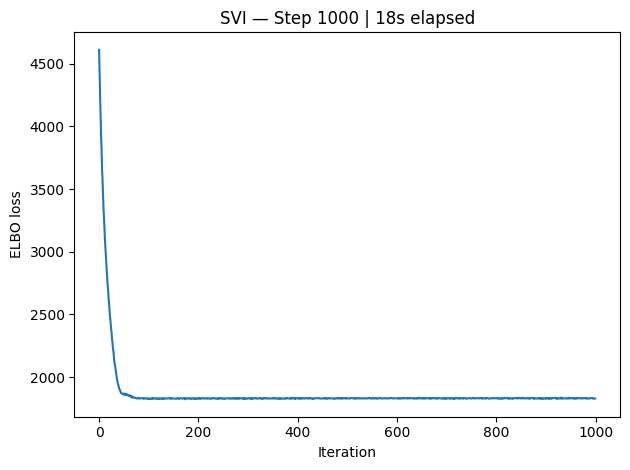

Step 1000: loss = 1828.84


In [11]:
pyro.set_rng_seed(seed)

optimizer = pyro.optim.Adam({'lr': 0.05})
svi = pyro.infer.SVI(model, guide, optimizer,
                     loss=pyro.infer.Trace_ELBO(num_particles=10))

niter  = 1000
losses = np.zeros(niter)
svi_time = time.time()

for step in range(niter):
    losses[step] = svi.step(a_idx, b_idx, wins, plays, nplayers)
    if (step + 1) % 100 == 0:
        clear_output(wait=True)
        plt.plot(losses[:step+1])
        plt.xlabel('Iteration'); plt.ylabel('ELBO loss')
        plt.title(f'SVI — Step {step+1} | {int(time.time()-svi_time)}s elapsed')
        plt.tight_layout(); plt.show()
        print(f'Step {step+1}: loss = {losses[step]:.2f}')

svi_time = time.time() - svi_time

### A3. Results

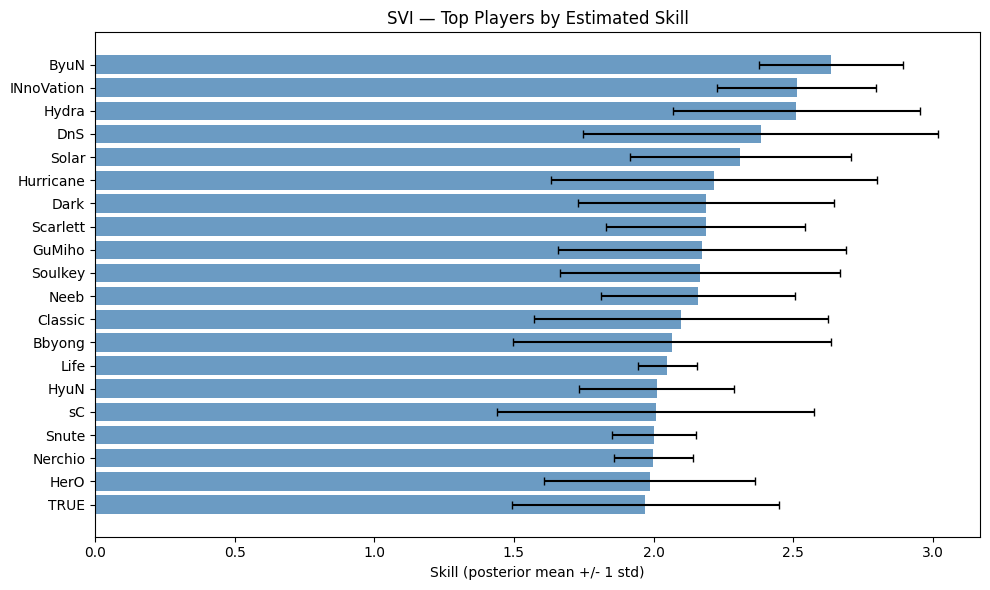

SVI validation accuracy: 0.610  (57355/94007)
SVI runtime: 19.0s
SVI mean posterior std: 0.7692


In [12]:
svi_mean = pyro.param('s_mean').detach().numpy().copy()
svi_std  = pyro.param('s_std').detach().numpy().copy()

# Skill rankings
order = np.argsort(svi_mean)[::-1]
top_k = min(20, nplayers)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(range(top_k), svi_mean[order[:top_k]],
        xerr=svi_std[order[:top_k]], align='center',
        color='steelblue', alpha=0.8, ecolor='black', capsize=3)
ax.set_yticks(range(top_k))
ax.set_yticklabels([playername[i] for i in order[:top_k]])
ax.invert_yaxis()
ax.set_xlabel('Skill (posterior mean +/- 1 std)')
ax.set_title('SVI — Top Players by Estimated Skill')
plt.tight_layout(); plt.show()

# Validation accuracy
svi_correct = sum(
    (a if svi_mean[a] > svi_mean[b] else b) == winner
    for a, b, winner in val_matches
)
svi_acc = svi_correct / len(val_matches)
print(f'SVI validation accuracy: {svi_acc:.3f}  ({svi_correct}/{len(val_matches)})')
print(f'SVI runtime: {svi_time:.1f}s')
print(f'SVI mean posterior std: {svi_std.mean():.4f}')

---
# Part B: MCMC (NUTS)

### B1. NumPyro Setup

In [13]:
numpyro.set_host_device_count(4)

a_jnp     = jnp.array(a_idx.numpy())
b_jnp     = jnp.array(b_idx.numpy())
wins_jnp  = jnp.array(wins.numpy())
plays_jnp = jnp.array(plays.numpy())

### B1. Single Chain (with Acceptance Rate Plot)

In [14]:
def np_model(a, b, wins, plays, nplayers):
    s = numpyro.sample("s", dist_np.Normal(jnp.zeros(nplayers), jnp.ones(nplayers)))
    prob = jax.nn.sigmoid(s[a] - s[b])
    numpyro.sample("obs", dist_np.Binomial(total_count=plays, probs=prob), obs=wins)

nuts_1chain = NUTS(np_model, adapt_step_size=True)

mcmc_1chain = MCMC(
    nuts_1chain,
    num_warmup=200,
    num_samples=500,
    num_chains=1,
    progress_bar=True,
)

sample: 100%|██████████| 700/700 [00:00<00:00, 744.86it/s, 15 steps of size 2.40e-01. acc. prob=0.87]


Single-chain MCMC finished in 3.0s


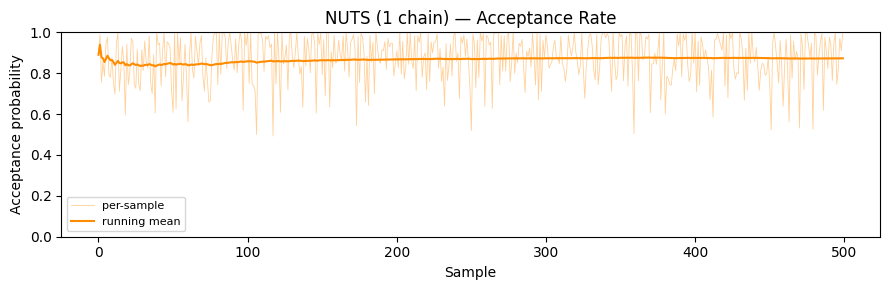

In [15]:
mcmc_time_1chain = time.time()

mcmc_1chain.run(
    jax.random.PRNGKey(seed),
    a_jnp, b_jnp, wins_jnp, plays_jnp, nplayers,
    extra_fields=("accept_prob",),
)

mcmc_time_1chain = time.time() - mcmc_time_1chain
print(f"Single-chain MCMC finished in {mcmc_time_1chain:.1f}s")

accept_probs = np.array(mcmc_1chain.get_extra_fields()["accept_prob"])
running_mean = np.cumsum(accept_probs) / np.arange(1, len(accept_probs) + 1)

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(accept_probs, lw=0.6, color='darkorange', alpha=0.4, label='per-sample')
ax.plot(running_mean, lw=1.5, color='darkorange', label='running mean')
ax.set_xlabel('Sample'); ax.set_ylabel('Acceptance probability')
ax.set_title('NUTS (1 chain) — Acceptance Rate')
ax.set_ylim(0, 1)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### B2. Two Chains

In [16]:
nuts_2chain = NUTS(np_model, adapt_step_size=True)

mcmc_2chain = MCMC(
    nuts_2chain,
    num_warmup=200,
    num_samples=500,
    num_chains=2,
    progress_bar=True,
)

Running chain 0:  20%|██        | 140/700 [00:00<00:00, 1234.90it/s]

Two-chain MCMC finished in 0.9s


Running chain 1: 100%|██████████| 700/700 [00:01<00:00, 562.63it/s] 


R-hat — min: 0.998  max: 1.008  mean: 1.000
ESS   — min: 480.9   max: 4420.1   mean: 1312.4


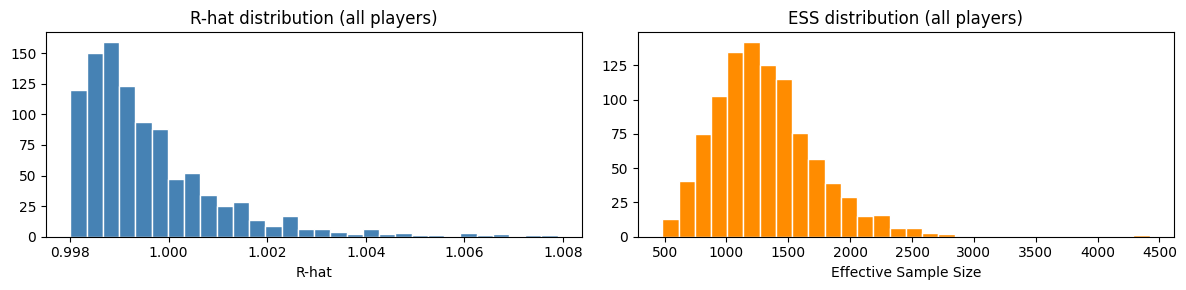

In [17]:
mcmc_time_2chain = time.time()

mcmc_2chain.run(
    jax.random.PRNGKey(seed),
    a_jnp, b_jnp, wins_jnp, plays_jnp, nplayers,
)

mcmc_time_2chain = time.time() - mcmc_time_2chain
print(f"Two-chain MCMC finished in {mcmc_time_2chain:.1f}s")

mcmc_summary = summary(mcmc_2chain.get_samples(group_by_chain=True))
s_rhat = np.array(mcmc_summary["s"]["r_hat"])
s_neff = np.array(mcmc_summary["s"]["n_eff"])

print(f"R-hat — min: {s_rhat.min():.3f}  max: {s_rhat.max():.3f}  mean: {s_rhat.mean():.3f}")
print(f"ESS   — min: {s_neff.min():.1f}   max: {s_neff.max():.1f}   mean: {s_neff.mean():.1f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3))
ax1.hist(s_rhat, bins=30, color='steelblue', edgecolor='white')
ax1.set_xlabel('R-hat')
ax1.set_title('R-hat distribution (all players)')

ax2.hist(s_neff, bins=30, color='darkorange', edgecolor='white')
ax2.set_xlabel('Effective Sample Size')
ax2.set_title('ESS distribution (all players)')
plt.tight_layout()
plt.show()

### B4. Four Chains

In [19]:
nuts_4chain = NUTS(np_model, adapt_step_size=True)

mcmc_4chain = MCMC(
    nuts_4chain,
    num_warmup=200,
    num_samples=500,
    num_chains=4,
    progress_bar=True,
)

Compiling.. :   0%|          | 0/700 [00:00<?, ?it/s]





Running chain 0:   0%|          | 0/700 [00:00<?, ?it/s]





Running chain 0:  15%|█▌        | 105/700 [00:00<00:00, 929.42it/s]

Four-chain MCMC finished in 1.0s



Running chain 0:  45%|████▌     | 315/700 [00:01<00:00, 1482.94it/s]


Running chain 0:  80%|████████  | 560/700 [00:01<00:00, 1795.25it/s]

Running chain 1: 100%|██████████| 700/700 [00:01<00:00, 540.16it/s] 


R-hat — min: 0.998  max: 1.006  mean: 1.000
ESS   — min: 1189.6   max: 4603.8   mean: 2558.0


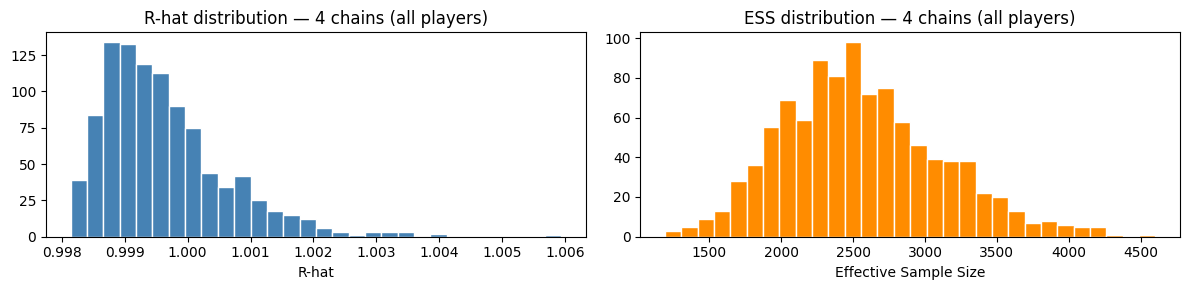

In [20]:
mcmc_time_4chain = time.time()

mcmc_4chain.run(
    jax.random.PRNGKey(seed),
    a_jnp, b_jnp, wins_jnp, plays_jnp, nplayers,
)

mcmc_time_4chain = time.time() - mcmc_time_4chain
print(f"Four-chain MCMC finished in {mcmc_time_4chain:.1f}s")

mcmc_summary_4 = summary(mcmc_4chain.get_samples(group_by_chain=True))
s_rhat_4 = np.array(mcmc_summary_4["s"]["r_hat"])
s_neff_4  = np.array(mcmc_summary_4["s"]["n_eff"])

print(f"R-hat — min: {s_rhat_4.min():.3f}  max: {s_rhat_4.max():.3f}  mean: {s_rhat_4.mean():.3f}")
print(f"ESS   — min: {s_neff_4.min():.1f}   max: {s_neff_4.max():.1f}   mean: {s_neff_4.mean():.1f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3))
ax1.hist(s_rhat_4, bins=30, color='steelblue', edgecolor='white')
ax1.set_xlabel('R-hat'); ax1.set_title('R-hat distribution — 4 chains (all players)')

ax2.hist(s_neff_4, bins=30, color='darkorange', edgecolor='white')
ax2.set_xlabel('Effective Sample Size')
ax2.set_title('ESS distribution — 4 chains (all players)')
plt.tight_layout()
plt.show()

### B5. Results

Final MCMC estimates from the four-chain run (most samples, strongest convergence).

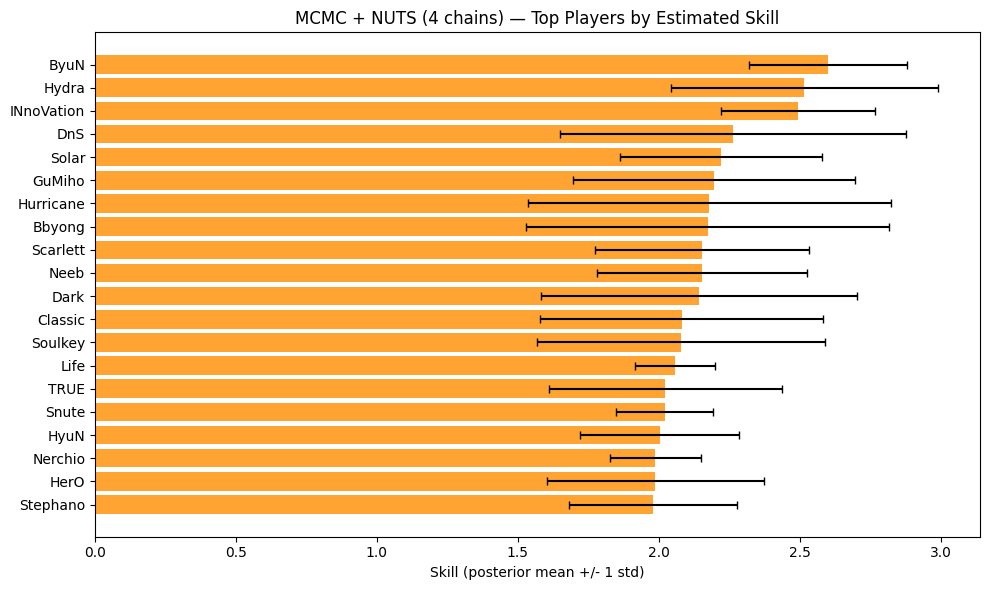

MCMC validation accuracy: 0.614  (57678/94007)
MCMC total runtime: 1.0s
MCMC mean posterior std: 0.7793


In [21]:
samples_4   = mcmc_4chain.get_samples()
s_samples_4 = np.array(samples_4["s"])    # (2000, nplayers) — 4 chains x 500 samples

mcmc_mean = s_samples_4.mean(axis=0)
mcmc_std  = s_samples_4.std(axis=0)
mcmc_time = mcmc_time_4chain

# Skill rankings
order_m = np.argsort(mcmc_mean)[::-1]
top_k   = min(20, nplayers)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(range(top_k), mcmc_mean[order_m[:top_k]],
        xerr=mcmc_std[order_m[:top_k]], align='center',
        color='darkorange', alpha=0.8, ecolor='black', capsize=3)
ax.set_yticks(range(top_k))
ax.set_yticklabels([playername[i] for i in order_m[:top_k]])
ax.invert_yaxis()
ax.set_xlabel('Skill (posterior mean +/- 1 std)')
ax.set_title('MCMC + NUTS (4 chains) — Top Players by Estimated Skill')
plt.tight_layout()
plt.show()

# Validation accuracy
mcmc_correct = sum(
    (a if mcmc_mean[a] > mcmc_mean[b] else b) == winner
    for a, b, winner in val_matches
)
mcmc_acc = mcmc_correct / len(val_matches)
print(f"MCMC validation accuracy: {mcmc_acc:.3f}  ({mcmc_correct}/{len(val_matches)})")
print(f"MCMC total runtime: {mcmc_time:.1f}s")
print(f"MCMC mean posterior std: {mcmc_std.mean():.4f}")

### B6. Comparison Across all MCMC Configurations

Comparing runtime, accuracy, uncertainty, and skill rankings across all 3 MCMC configurations

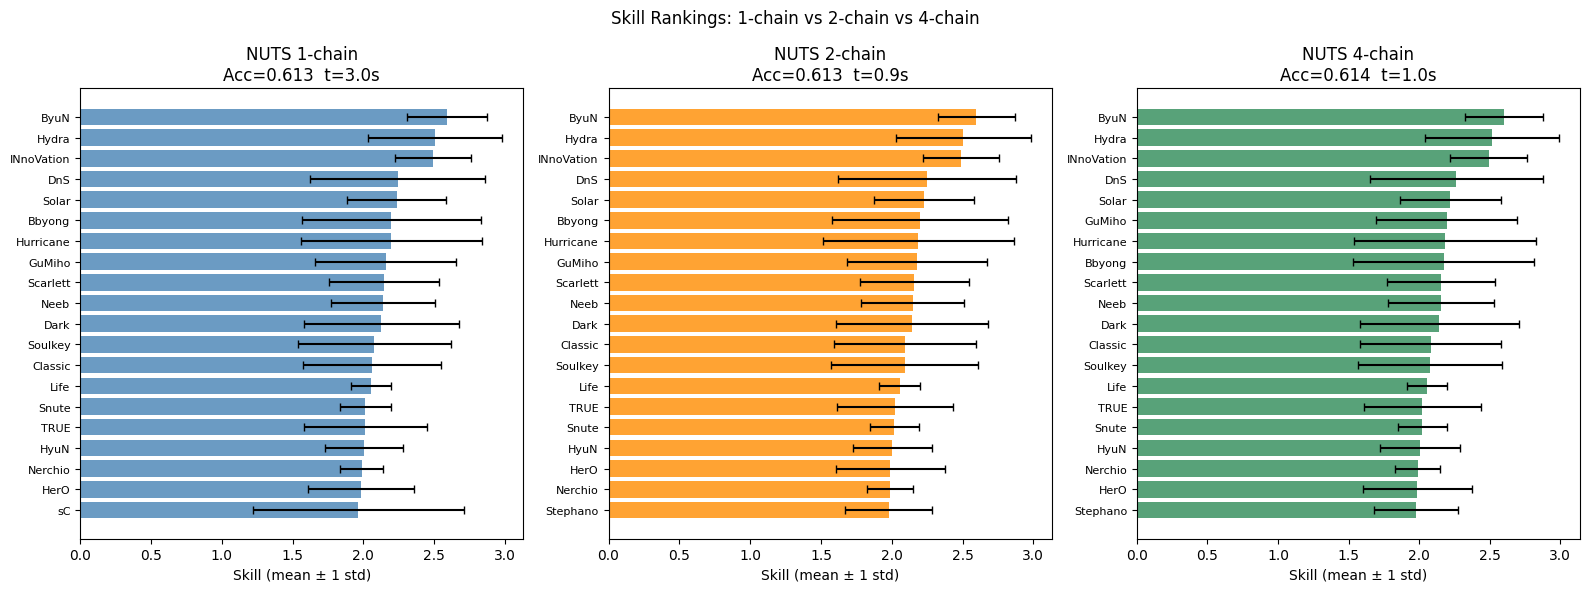

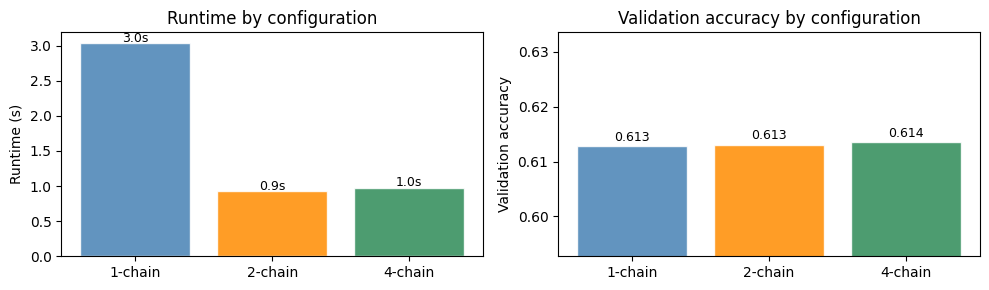

In [22]:
s_samples_1 = np.array(mcmc_1chain.get_samples()["s"])
s_samples_2 = np.array(mcmc_2chain.get_samples()["s"])
s_samples_4 = np.array(mcmc_4chain.get_samples()["s"])

mean_1 = s_samples_1.mean(axis=0); std_1 = s_samples_1.std(axis=0)
mean_2 = s_samples_2.mean(axis=0); std_2 = s_samples_2.std(axis=0)
mean_4 = s_samples_4.mean(axis=0); std_4 = s_samples_4.std(axis=0)

def val_acc(mean):
    correct = sum(
        (a if mean[a] > mean[b] else b) == winner
        for a, b, winner in val_matches
    )
    return correct / len(val_matches)

acc_1, acc_2, acc_4 = val_acc(mean_1), val_acc(mean_2), val_acc(mean_4)

configs = [
    (mean_1, std_1, mcmc_time_1chain, acc_1, '1-chain', 'steelblue'),
    (mean_2, std_2, mcmc_time_2chain, acc_2, '2-chain', 'darkorange'),
    (mean_4, std_4, mcmc_time_4chain, acc_4, '4-chain', 'seagreen'),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 6))
for ax, (mean, std, t, acc, label, color) in zip(axes, configs):
    order = np.argsort(mean)[::-1][:top_k]
    ax.barh(range(top_k), mean[order], xerr=std[order],
            align='center', color=color, alpha=0.8, ecolor='black', capsize=3)
    ax.set_yticks(range(top_k))
    ax.set_yticklabels([playername[i] for i in order], fontsize=8)
    ax.invert_yaxis()
    ax.set_xlabel('Skill (mean ± 1 std)')
    ax.set_title(f'NUTS {label}\nAcc={acc:.3f}  t={t:.1f}s')
plt.suptitle('Skill Rankings: 1-chain vs 2-chain vs 4-chain', fontsize=12)
plt.tight_layout()
plt.show()

labels   = [c[4] for c in configs]
runtimes = [c[2] for c in configs]
accs     = [c[3] for c in configs]
colors   = [c[5] for c in configs]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3))
ax1.bar(labels, runtimes, color=colors, edgecolor='white', alpha=0.85)
ax1.set_ylabel('Runtime (s)'); ax1.set_title('Runtime by configuration')
for i, v in enumerate(runtimes):
    ax1.text(i, v + 0.02, f'{v:.1f}s', ha='center', fontsize=9)

ax2.bar(labels, accs, color=colors, edgecolor='white', alpha=0.85)
ax2.set_ylabel('Validation accuracy'); ax2.set_title('Validation accuracy by configuration')
ax2.set_ylim(min(accs) - 0.02, max(accs) + 0.02)
for i, v in enumerate(accs):
    ax2.text(i, v + 0.001, f'{v:.3f}', ha='center', fontsize=9)
plt.tight_layout()
plt.show()

### B7. Comparison Across Multi-Chain MCMC Configurations

Comparing R-hat and ESS across MCMC 2-chain and 4-chain

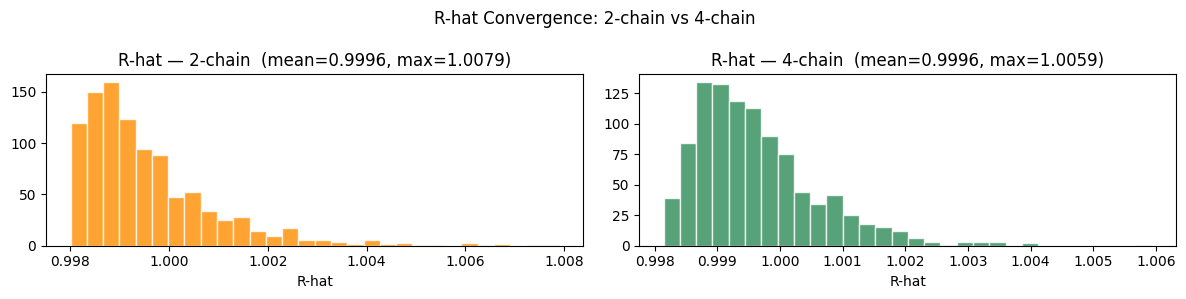

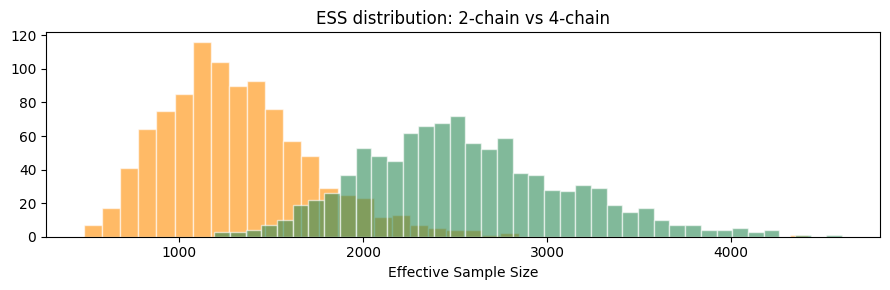

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for ax, rhat, label, color in [
    (axes[0], s_rhat,   '2-chain', 'darkorange'),
    (axes[1], s_rhat_4, '4-chain', 'seagreen'),
]:
    ax.hist(rhat.flatten(), bins=30, color=color, edgecolor='white', alpha=0.8)
    ax.set_xlabel('R-hat')
    ax.set_title(f'R-hat — {label}  (mean={rhat.mean():.4f}, max={rhat.max():.4f})')
plt.suptitle('R-hat Convergence: 2-chain vs 4-chain', fontsize=12)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 3))
ax.hist(s_neff.flatten(),   bins=40, alpha=0.6, color='darkorange',
        edgecolor='white', label=f'2-chain  (mean={s_neff.mean():.0f})')
ax.hist(s_neff_4.flatten(), bins=40, alpha=0.6, color='seagreen',
        edgecolor='white', label=f'4-chain  (mean={s_neff_4.mean():.0f})')
ax.set_xlabel('Effective Sample Size')
ax.set_title('ESS distribution: 2-chain vs 4-chain')
plt.tight_layout()
plt.show()

---
# Part C: Comparison

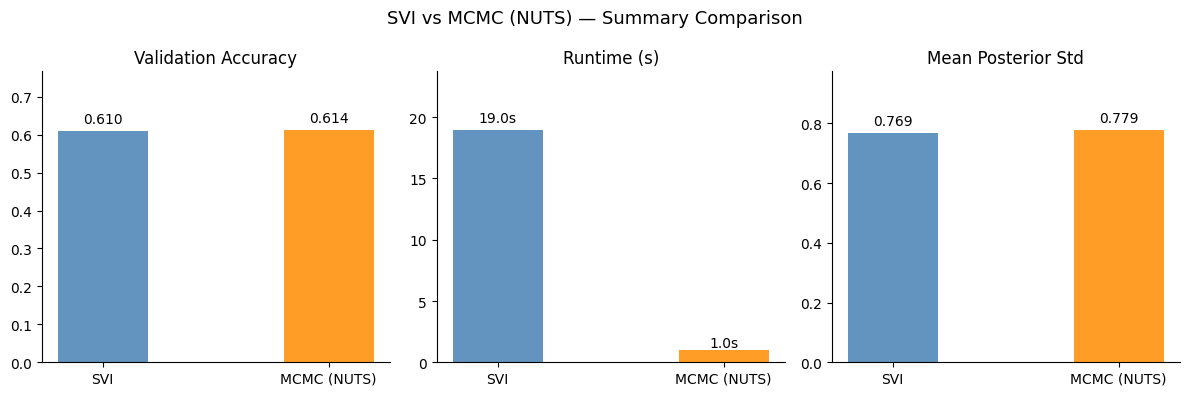

In [24]:
methods = ['SVI', 'MCMC (NUTS)']
colors  = ['steelblue', 'darkorange']

metrics = {
    'Validation Accuracy': [svi_acc,        mcmc_acc],
    'Runtime (s)':         [svi_time,        mcmc_time],
    'Mean Posterior Std':  [svi_std.mean(),  mcmc_std.mean()],
}

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (title, vals) in zip(axes, metrics.items()):
    bars = ax.bar(methods, vals, color=colors, alpha=0.85, width=0.4)
    for bar, val in zip(bars, vals):
        label = f'{val:.1f}s' if title == 'Runtime (s)' else f'{val:.3f}'
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() * 1.02,
                label, ha='center', va='bottom', fontsize=10)
    ax.set_title(title)
    ax.set_ylim(0, max(vals) * 1.25)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.suptitle('SVI vs MCMC (NUTS) — Summary Comparison', fontsize=13)
plt.tight_layout(); plt.show()

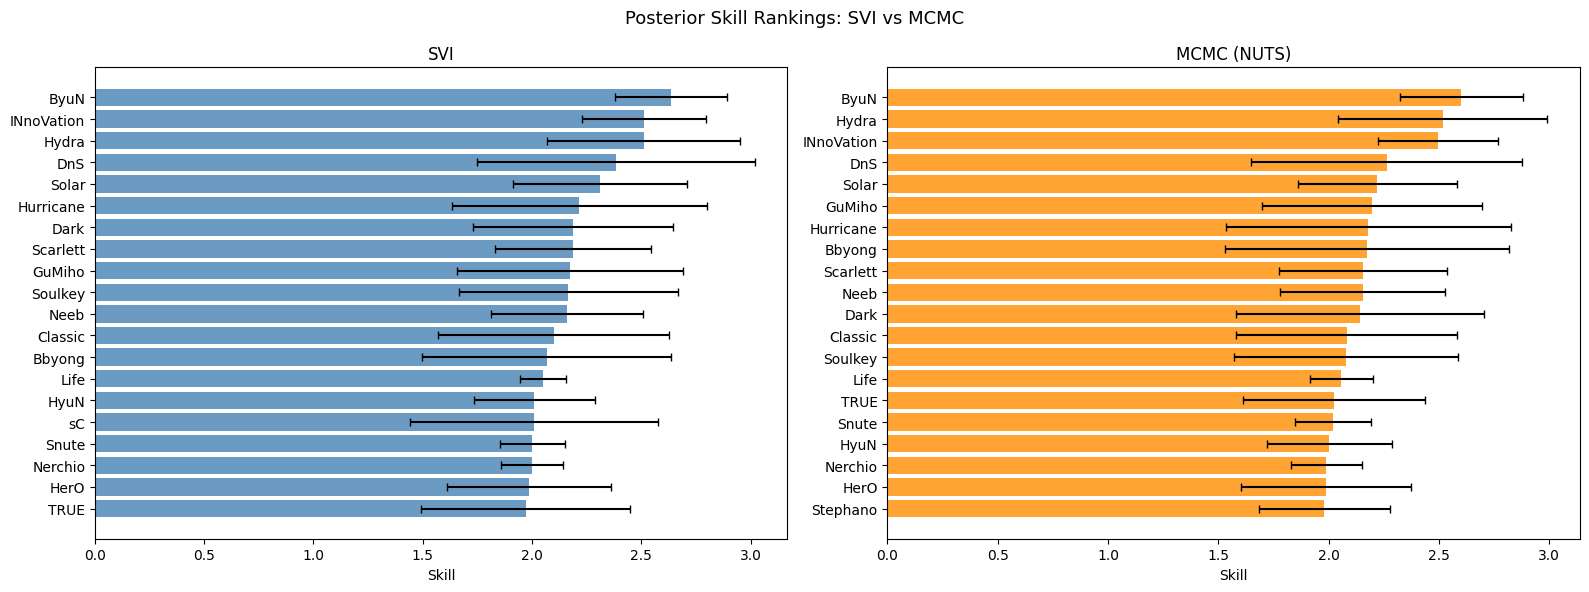

In [25]:
# Side-by-side skill ranking comparison (top 20)
order_svi  = np.argsort(svi_mean)[::-1][:top_k]
order_mcmc = np.argsort(mcmc_mean)[::-1][:top_k]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

ax1.barh(range(top_k), svi_mean[order_svi], xerr=svi_std[order_svi],
         align='center', color='steelblue', alpha=0.8, ecolor='black', capsize=3)
ax1.set_yticks(range(top_k))
ax1.set_yticklabels([playername[i] for i in order_svi])
ax1.invert_yaxis()
ax1.set_xlabel('Skill'); ax1.set_title('SVI')

ax2.barh(range(top_k), mcmc_mean[order_mcmc], xerr=mcmc_std[order_mcmc],
         align='center', color='darkorange', alpha=0.8, ecolor='black', capsize=3)
ax2.set_yticks(range(top_k))
ax2.set_yticklabels([playername[i] for i in order_mcmc])
ax2.invert_yaxis()
ax2.set_xlabel('Skill'); ax2.set_title('MCMC (NUTS)')

plt.suptitle('Posterior Skill Rankings: SVI vs MCMC', fontsize=13)
plt.tight_layout(); plt.show()

---
# Part D: Additional Experiments — Effect of Training Data Size

We vary `pKeep` (the fraction of training matches retained) and measure how validation accuracy changes for both SVI and MCMC.

In [ ]:
def build_data(pKeep, lines, playerid, nplayers, nEdge=3, nKeep=5):
    np.random.seed(seed)
    nplays = np.zeros((nplayers, nplayers))
    nwins  = np.zeros((nplayers, nplayers))
    for line in lines:
        csv = line.split(',')
        if len(csv) != 10: continue
        a, b = playerid[csv[1]], playerid[csv[4]]
        aw, bw = csv[2] == '[winner]', csv[5] == '[winner]'
        if np.random.rand() < pKeep:
            if (nplays[a,b] < nKeep) and (
                (nplays[a,:]>0).sum() < nEdge or (nplays[:,b]>0).sum() < nEdge
            ):
                nplays[a,b] += 1; nplays[b,a] += 1
                nwins[a,b]  += aw; nwins[b,a]  += bw
    pairs = [(a, b) for a in range(nplayers) for b in range(a+1, nplayers) if nplays[a,b] > 0]
    a_t = torch.tensor([p[0] for p in pairs], dtype=torch.long)
    b_t = torch.tensor([p[1] for p in pairs], dtype=torch.long)
    w_t = torch.tensor([nwins[p[0],p[1]]  for p in pairs], dtype=torch.float)
    p_t = torch.tensor([nplays[p[0],p[1]] for p in pairs], dtype=torch.float)
    return a_t, b_t, w_t, p_t

def run_svi(a_t, b_t, w_t, p_t, nplayers, niter=1000):
    pyro.get_param_store().clear()
    pyro.set_rng_seed(seed)
    opt = pyro.optim.Adam({'lr': 0.05})
    svi = pyro.infer.SVI(model, guide, opt, loss=pyro.infer.Trace_ELBO(num_particles=10))
    for _ in range(niter):
        svi.step(a_t, b_t, w_t, p_t, nplayers)
    s = pyro.param('s_mean').detach().numpy()
    return s

def run_mcmc(a_t, b_t, w_t, p_t, nplayers, num_samples=500, warmup=200):
    pyro.set_rng_seed(seed)
    kernel = pyro.infer.NUTS(model, adapt_step_size=True, jit_compile=False)
    mcmc   = pyro.infer.MCMC(kernel, num_samples=num_samples,
                              warmup_steps=warmup, num_chains=1, disable_progbar=True)
    mcmc.run(a_t, b_t, w_t, p_t, nplayers)
    s = mcmc.get_samples()['s'].numpy().mean(axis=0)
    return s

def accuracy(s_mean, val_matches):
    correct = sum((a if s_mean[a] > s_mean[b] else b) == w for a, b, w in val_matches)
    return correct / len(val_matches)

pkeep_vals = [0.2, 0.4, 0.6, 0.8, 1.0]
svi_accs, mcmc_accs = [], []

for pk in pkeep_vals:
    print(f'pKeep={pk:.1f}...', end=' ', flush=True)
    a_t, b_t, w_t, p_t = build_data(pk, lines, playerid, nplayers)

    s_svi  = run_svi(a_t, b_t, w_t, p_t, nplayers)
    s_mcmc = run_mcmc(a_t, b_t, w_t, p_t, nplayers)

    svi_accs.append(accuracy(s_svi,  val_matches))
    mcmc_accs.append(accuracy(s_mcmc, val_matches))
    print(f'SVI={svi_accs[-1]:.3f}  MCMC={mcmc_accs[-1]:.3f}')

print('Done.')

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(pkeep_vals, svi_accs,  'o-', color='steelblue',  label='SVI',        lw=2)
ax.plot(pkeep_vals, mcmc_accs, 's-', color='darkorange', label='MCMC (NUTS)', lw=2)
ax.set_xlabel('Fraction of Training Data (pKeep)')
ax.set_ylabel('Validation Accuracy')
ax.set_title('Effect of Training Data Size on Prediction Accuracy')
ax.set_xticks(pkeep_vals)
ax.set_xticklabels([f'{int(p*100)}%' for p in pkeep_vals])
ax.legend()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout(); plt.show()

### D2. Effect of Graph Connectivity (nEdge)

`nEdge` controls the maximum number of distinct opponents each player faces. Higher values produce a more connected match graph, giving the model more paths to compare players transitively.

In [ ]:
nedge_vals = [1, 2, 3, 5, 8]
svi_accs_e, mcmc_accs_e = [], []

for ne in nedge_vals:
    print(f'nEdge={ne}...', end=' ', flush=True)
    a_t, b_t, w_t, p_t = build_data(1.0, lines, playerid, nplayers, nEdge=ne, nKeep=5)

    s_svi  = run_svi(a_t, b_t, w_t, p_t, nplayers)
    s_mcmc = run_mcmc(a_t, b_t, w_t, p_t, nplayers)

    svi_accs_e.append(accuracy(s_svi,  val_matches))
    mcmc_accs_e.append(accuracy(s_mcmc, val_matches))
    print(f'SVI={svi_accs_e[-1]:.3f}  MCMC={mcmc_accs_e[-1]:.3f}')

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(nedge_vals, svi_accs_e,  'o-', color='steelblue',  label='SVI',        lw=2)
ax.plot(nedge_vals, mcmc_accs_e, 's-', color='darkorange', label='MCMC (NUTS)', lw=2)
ax.set_xlabel('Max Opponents per Player (nEdge)')
ax.set_ylabel('Validation Accuracy')
ax.set_title('Effect of Graph Connectivity on Prediction Accuracy')
ax.set_xticks(nedge_vals)
ax.legend()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout(); plt.show()